# Deliverable 3 — Image Captioning (CNN + RNN)

**Goal.** Write a short sentence that describes a photo, e.g. "*a man riding a wave on a surfboard*". TouNum can
then search its scanned photos by their content. This notebook is the last step of the workflow:

```txt
 image ──> [D1] photo or not? ──> [D2] denoising ──> [D3] caption (this notebook)
             not a photo: set aside
```

The complete chain, on any folder of images, is in `04_pipeline.ipynb` (used for the demo).

**Method.** We follow the tutorial **Hvass-Labs #22 "Image Captioning"**
(https://github.com/Hvass-Labs/TensorFlow-Tutorials/blob/master/22_Image_Captioning.ipynb). Two parts:
- a **CNN** (InceptionV3, already trained on ImageNet) turns each image into a vector of 2,048 numbers;
- an **RNN** (3 GRU layers) starts from this vector and writes the caption **word by word**.

Dataset: **MS COCO 2017**, about 118,000 photos with 5 human captions each.

**Differences with the tutorial**

| Hvass #22 | Here | Why |
|---|---|---|
| 118k training images | **30,000** images (90 % train, 10 % validation) | faster training |
| no test set | val2017 (5,000 images) = **test set** | honest final score |
| VGG16 (`fc2`, 4,096 numbers) | **InceptionV3** (v1-v3), then **ConvNeXt-Base** (v4) | more accurate CNNs: better description of the image |
| pixels in [0, 1] for the CNN | the CNN's own `preprocess_input` | the input the CNN was trained with |
| `Tokenizer` (removed in Keras 3) | `TextVectorization` | Keras 3 |
| padding counted in the loss | padding **masked** | only real words count |
| no validation, 20 epochs | validation, EarlyStopping, **BLEU** and **CIDEr** scores | to detect overfitting, measure the sentences |
| RMSprop, no dropout | Adam + gradient clipping, **dropout** 0.3 | less overfitting (v2) |
| 1 vector per image | **one vector per region** + **attention** inside the GRU (v4) | the network looks at the right region for each word |
| greedy only | greedy **and beam search** (5 sentences) | better sentences |

In [9]:
import tensorflow as tf, keras
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.21.0 | Keras 3.15.1


## 1. Imports and Configuration

In [10]:
print("[Block 1] Imports and configuration : starting...")

import json, re, time, urllib.request, warnings, zipfile
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import imageio.v3 as iio          # required by the assignment (image info)
import tensorflow as tf
import keras
from keras import layers, ops
from keras.applications import ConvNeXtBase, InceptionV3, VGG16, convnext, inception_v3, vgg16
from sklearn.model_selection import train_test_split
from nltk.translate.bleu_score import corpus_bleu, sentence_bleu, SmoothingFunction
from pycocoevalcap.cider.cider import Cider   # CIDEr score (section 7)

warnings.filterwarnings("ignore", module="nltk")   # hide nltk BLEU warnings

# Fixed seed: same results at every run
SEED = 42
keras.utils.set_random_seed(SEED)   # Python, NumPy and TensorFlow seeds

# Paths (relative to the notebook folder, /workspace in Docker)
ROOT = Path("")
RAW = ROOT / "data_raw"            # original data
COCO = RAW / "coco"                # MS COCO 2017
DATA = ROOT / "data"               # generated files (can be deleted)
FEATURES = DATA / "coco_features"  # CNN vectors (section 3)
RESULTS = ROOT / "results"         # models, vocabulary, result tables
LOGS = RESULTS / "logs"            # training logs
for folder in (COCO, FEATURES, RESULTS, LOGS):
    folder.mkdir(parents=True, exist_ok=True)

# Data
N_TRAIN_IMAGES = 118_000   # images taken from train2017 (out of 118,287)
VAL_SHARE = 0.10          # share kept for validation

# Image preprocessing (section 3)
# Pretrained CNN (section 3):
#   "InceptionV3"       1 vector per image (v1, v2)        "VGG16"  the tutorial's choice
#   "InceptionV3_grid"  64 regions (8 x 8) per image       "ConvNeXtBase_grid"  49 regions (7 x 7), more accurate CNN (v4)
ENCODER = "ConvNeXtBase_grid"
ATTENTION = ENCODER.endswith("_grid")   # True: decoder with attention (section 5)
FEATURE_BATCH = 64        # batch size for the CNN

# Text preprocessing (section 4)
MARK_START, MARK_END = "ssss", "eeee"   # start / end words (from the tutorial)
NUM_WORDS = 10_000        # vocabulary size

# Network and training (tutorial values, except the ones marked v2)
STATE_SIZE = 512          # GRU memory size
EMBEDDING_SIZE = 256      # size of a word vector (v2, tutorial: 128)
DROPOUT = 0.3             # share of values set to 0 during training, against overfitting (v2)
BATCH = 384               # captions per training batch
LR = 1e-3                 # learning rate of Adam (v2, tutorial: RMSprop)
EPOCHS = 50               # maximum (EarlyStopping stops before)
BEAM = 5                  # beam search width (number of sentences kept)

print("[Block 1] OK")

[Block 1] Imports and configuration : starting...
[Block 1] OK


## 2. The Data: MS COCO 2017

### 2.1 Download (first run only)

3 archives: annotations (250 MB), validation images (800 MB), training images (18 GB, ~30 min).
An archive already on disk is not downloaded again.

In [11]:
print("[Block 2a] Download : starting...")

COCO_URL = "http://images.cocodataset.org/"
ARCHIVES = {"annotations": "annotations/annotations_trainval2017.zip",
            "val": "zips/val2017.zip",
            "train": "zips/train2017.zip"}

def download(url_path):
    # Download an archive, unless it is already there
    dest = COCO / Path(url_path).name
    if dest.exists():
        print(f"  {dest.name}: already downloaded ({dest.stat().st_size / 1e9:.2f} GB)")
        return dest
    part = dest.with_suffix(".part")   # renamed only when complete
    def progress(blocks, block_size, total):
        print(f"\r  {dest.name}: {blocks * block_size / 1e9:.2f} / {total / 1e9:.2f} GB", end="")
    urllib.request.urlretrieve(COCO_URL + url_path, part, progress)
    part.replace(dest)
    print()
    return dest

archives = {name: download(path) for name, path in ARCHIVES.items()}

# We only need the 2 caption files
for split in ("train2017", "val2017"):
    member = f"annotations/captions_{split}.json"
    if not (COCO / member).exists():
        with zipfile.ZipFile(archives["annotations"]) as z:
            z.extract(member, COCO)
print("  caption files:", sorted(p.name for p in (COCO / "annotations").glob("captions_*.json")))

print("[Block 2a] OK")

[Block 2a] Download : starting...
  annotations_trainval2017.zip: already downloaded (0.25 GB)
  val2017.zip: already downloaded (0.82 GB)
  train2017.zip: already downloaded (19.34 GB)
  caption files: ['captions_train2017.json', 'captions_val2017.json']
[Block 2a] OK


### 2.2 The captions

The JSON files contain the images and the captions (linked by `image_id`). We build a table with one row per
image and its list of captions.

In [12]:
print("[Block 2b] Captions : starting...")

def load_coco(split):
    # One row per image, with the list of its captions
    with open(COCO / "annotations" / f"captions_{split}.json") as f:
        ann = json.load(f)
    images = pd.DataFrame(ann["images"])[["id", "file_name", "width", "height"]]
    captions = pd.DataFrame(ann["annotations"]).groupby("image_id")["caption"].apply(list)
    images["captions"] = images["id"].map(captions)
    images["path"] = [(COCO / split / f).as_posix() for f in images["file_name"]]
    return images.dropna(subset=["captions"]).sort_values("id").reset_index(drop=True)

coco_train = load_coco("train2017")
coco_test = load_coco("val2017")   # our test set

for name, table in (("train2017", coco_train), ("val2017", coco_test)):
    n_caps = table["captions"].str.len()
    print(f"  {name}: {len(table):6d} images, {n_caps.sum():6d} captions "
          f"(per image: min {n_caps.min()}, max {n_caps.max()}, mean {n_caps.mean():.2f})")
display(coco_train.head(3)[["id", "file_name", "width", "height", "captions"]])

print("[Block 2b] OK")

[Block 2b] Captions : starting...
  train2017: 118287 images, 591753 captions (per image: min 5, max 7, mean 5.00)
  val2017:   5000 images,  25014 captions (per image: min 5, max 7, mean 5.00)


,id,file_name,width,height,captions
0,9,000000000009.jpg,640,480,[Closeup of bins of food that include broccoli...
1,25,000000000025.jpg,640,426,[A giraffe eating food from the top of the tre...
2,30,000000000030.jpg,640,428,"[A flower vase is sitting on a porch stand., W..."


[Block 2b] OK


### 2.3 Subset and split

We take `N_TRAIN_IMAGES` random images and split them **by image**: the 5 captions of an image stay in the same
part (no leak between train and validation). The test set is val2017. Only the images we use are extracted.

In [13]:
print("[Block 2c] Subset, split and images : starting...")

subset = coco_train.sample(n=min(N_TRAIN_IMAGES, len(coco_train)), random_state=SEED)
train_df, val_df = train_test_split(subset, test_size=VAL_SHARE, random_state=SEED)
train_df, val_df = train_df.sort_values("id").reset_index(drop=True), val_df.sort_values("id").reset_index(drop=True)
test_df = coco_test
assert not set(train_df["id"]) & set(val_df["id"]), "the same image is in train and validation"

def extract_images(archive, split, table):
    # Extract only the missing images
    missing = [f for f in table["file_name"] if not (COCO / split / f).exists()]
    if missing:
        print(f"  {split}: extracting {len(missing)} images...")
        with zipfile.ZipFile(archive) as z:
            for f in missing:
                z.extract(f"{split}/{f}", COCO)
    print(f"  {split}: {len(table)} images on disk")

extract_images(archives["train"], "train2017", pd.concat([train_df, val_df]))
extract_images(archives["val"], "val2017", test_df)

splits = pd.DataFrame({"images": [len(train_df), len(val_df), len(test_df)],
                       "captions": [train_df.captions.str.len().sum(), val_df.captions.str.len().sum(),
                                    test_df.captions.str.len().sum()]}, index=["train", "val", "test"])
display(splits)

# Quick check with ImageIO: colour mode and size
sample = subset.sample(500, random_state=SEED)
modes = Counter(iio.immeta(p).get("mode") for p in sample["path"])
print("  colour modes (500 images):", dict(modes), "-> grey images (L) are converted to RGB")
print(f"  median size: {int(subset.width.median())} x {int(subset.height.median())} pixels")

print("[Block 2c] OK")

[Block 2c] Subset, split and images : starting...
  train2017: 118000 images on disk
  val2017: 5000 images on disk


,images,captions
train,106200,531280
val,11800,59038
test,5000,25014


  colour modes (500 images): {'RGB': 498, 'L': 2} -> grey images (L) are converted to RGB
  median size: 640 x 480 pixels
[Block 2c] OK


### 2.4 Visual inspection

The captions describe the main objects, the action and the place, always in the same simple style. The network
will learn this style, and can only describe what is common in COCO (people, animals, vehicles, food, rooms).

[Block 2d] Visual inspection : starting...


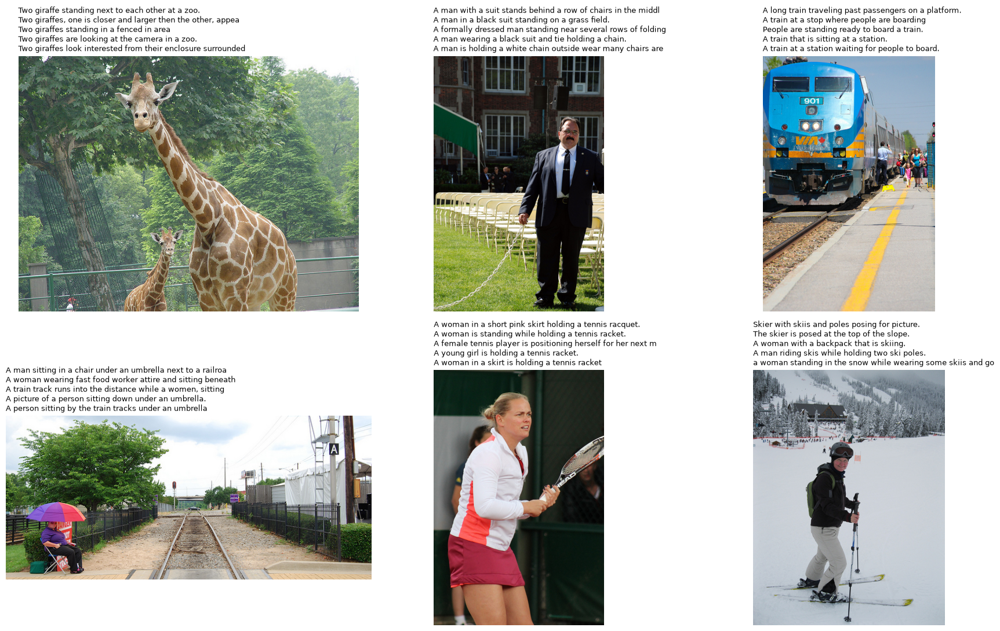

[Block 2d] OK


In [14]:
print("[Block 2d] Visual inspection : starting...")

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
for ax, (_, row) in zip(axes.flat, train_df.sample(6, random_state=SEED).iterrows()):
    ax.imshow(iio.imread(row["path"]), cmap="gray")
    ax.axis("off")
    ax.set_title("\n".join(c.strip()[:60] for c in row["captions"][:5]), fontsize=9, loc="left")
plt.tight_layout()
plt.show()

print("[Block 2d] OK")

## 3. Image Preprocessing: the CNN (InceptionV3, then ConvNeXt)

The CNN is already trained on ImageNet (1.2 million photos). We remove its last layer (the 1,000 classes) and keep
the layer before: a vector that describes the content of the image. The CNN is **frozen** (not trained).

The tutorial uses VGG16. We use **InceptionV3**, which is better on every point that matters here:

| | VGG16 (tutorial) | InceptionV3 (ours) |
|---|---|---|
| ImageNet accuracy (top-1) | 71.3 % | 77.9 % |
| weights | 138 M | 24 M |
| input size | 224 x 224 | 299 x 299 |
| layer used | `fc2` | `avg_pool` (global average pooling) |
| vector per image | 4,096 numbers | 2,048 numbers |

```txt
image -> resize 299 x 299 -> preprocess_input (pixels in [-1, 1]) -> InceptionV3 -> avg_pool (2048)
```

`ENCODER = "VGG16"` (section 1) gives back the tutorial's setup, to compare the two. Each CNN has its own cache
files and its own model file, so both can be kept.

The CNN is slow but its output never changes, so we run it **once** per image and save the vectors to disk
(`data/coco_features/*.npy`). Training then reads small vectors instead of images.

**Grid of regions (attention model).** `avg_pool` is the **mean** of the last convolution block `mixed10`,
which has 8 x 8 = 64 positions, one vector of 2,048 numbers per region of the image. The mean loses *where*
things are. With `ENCODER = "InceptionV3_grid"` we keep the 64 vectors, so the decoder can look at one region
per word (section 5).

```txt
InceptionV3 ──> mixed10 (8 x 8 x 2048) ──> mean ──> avg_pool (2048)      1 vector per image
                       └──────────────> reshape ──> grid (64 x 2048)     64 vectors per image
```

The grid is 64 times bigger: **27 GB** for the training images, more than the RAM. The file stays on disk
and NumPy reads only the rows of each batch (`mmap_mode="r"`, *memory map*).

**v4: a more recent CNN, ConvNeXt-Base (2022).** The CNN is the "eye" of the network: the decoder can only
describe what the CNN has seen. InceptionV3 dates from 2015. ConvNeXt-Base was trained on 14 million images
(ImageNet-22k) before ImageNet, and recognises objects much better:

| | InceptionV3 | ConvNeXt-Base |
|---|---|---|
| year | 2015 | 2022 |
| ImageNet accuracy (top-1) | 77.9 % | 85.3 % |
| input size | 299 x 299 | 224 x 224 |
| grid | 8 x 8 = 64 regions of 2,048 numbers | 7 x 7 = 49 regions of 1,024 numbers |
| size of the training grid | 27 GB | 11 GB |

We take the last block before its classifier, with the same normalisation (`LayerNormalization`) as the
classifier uses.

In [15]:
print("[Block 3] CNN features : starting...")

AUTOTUNE = tf.data.AUTOTUNE

def build_encoder(name):
    # Pretrained CNN without its last layer, and its own preprocessing function
    if name == "InceptionV3":
        cnn = InceptionV3(include_top=True, weights="imagenet")
        return keras.Model(cnn.input, cnn.get_layer("avg_pool").output, name="InceptionV3_avg_pool"), inception_v3.preprocess_input
    if name == "InceptionV3_grid":
        # Last convolution block before the mean: 8 x 8 regions -> 64 vectors of 2048 numbers
        cnn = InceptionV3(include_top=True, weights="imagenet")
        block = cnn.get_layer("mixed10").output
        grid = layers.Reshape((-1, block.shape[-1]), name="regions")(block)
        return keras.Model(cnn.input, grid, name="InceptionV3_mixed10"), inception_v3.preprocess_input
    if name == "ConvNeXtBase_grid":
        # Last block before the classifier: 7 x 7 regions -> 49 vectors of 1024 numbers
        cnn = ConvNeXtBase(include_top=True, weights="imagenet")
        block = cnn.get_layer("convnext_base_head_gap").input                  # (7, 7, 1024)
        block = cnn.get_layer("convnext_base_head_layernorm")(block)           # same normalisation as the classifier
        grid = layers.Reshape((-1, block.shape[-1]), name="regions")(block)
        return keras.Model(cnn.input, grid, name="ConvNeXtBase_grid"), convnext.preprocess_input
    if name == "VGG16":
        cnn = VGG16(include_top=True, weights="imagenet")
        return keras.Model(cnn.input, cnn.get_layer("fc2").output, name="VGG16_fc2"), vgg16.preprocess_input
    raise ValueError(f"unknown encoder {name}")

encoder, preprocess_input = build_encoder(ENCODER)
IMG_SIZE = tuple(encoder.input_shape[1:3])   # 299 x 299 for InceptionV3, 224 x 224 for VGG16
FEATURE_SHAPE = tuple(encoder.output_shape[1:])   # (2048,), (4096,) for VGG16, (64, 2048) for the grid
FEATURE_SIZE = FEATURE_SHAPE[-1]
print(f"  encoder {encoder.name}: {encoder.count_params():,} weights (frozen), input {IMG_SIZE}, "
      f"output: {FEATURE_SHAPE} per image")

def load_for_encoder(path):
    # Read the image in RGB, resize to the CNN input size, apply the CNN preprocessing
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, IMG_SIZE)
    return preprocess_input(img)

def image_features(table, name):
    # CNN vectors of the images, computed once then read from disk (one file per CNN)
    cache, order = FEATURES / f"{encoder.name}_{name}.npy", FEATURES / f"{encoder.name}_{name}.csv"
    paths = table["path"].tolist()
    if cache.exists() and order.exists() and pd.read_csv(order)["path"].tolist() == paths:
        print(f"  {name}: read from {cache}")
    else:
        start = time.time()
        ds = tf.data.Dataset.from_tensor_slices(paths).map(load_for_encoder, num_parallel_calls=AUTOTUNE)
        part = cache.with_suffix(".part.npy")   # renamed only when complete
        out = np.lib.format.open_memmap(part, mode="w+", dtype="float16", shape=(len(paths), *FEATURE_SHAPE))
        done = 0
        for batch in ds.batch(FEATURE_BATCH).prefetch(AUTOTUNE):   # written batch by batch: never all in RAM
            f = encoder.predict_on_batch(batch)
            out[done:done + len(f)] = f
            done += len(f)
        out.flush(); del out
        part.replace(cache)
        pd.DataFrame({"path": paths}).to_csv(order, index=False)   # to check the order next time
        print(f"  {name}: {len(paths)} images in {time.time() - start:.0f} s "
              f"({(time.time() - start) / len(paths) * 1000:.1f} ms per image)")
    return np.load(cache, mmap_mode="r" if ATTENTION else None)   # grid: stays on disk, rows read when needed

# Name of the feature files of each CNN (used in section 7 to evaluate all the saved models)
FEATURE_FILES = {"InceptionV3": "InceptionV3_avg_pool", "InceptionV3_grid": "InceptionV3_mixed10",
                 "VGG16": "VGG16_fc2", "ConvNeXtBase_grid": "ConvNeXtBase_grid"}
assert FEATURE_FILES[ENCODER] == encoder.name

def pooled(features, chunk=2000):
    # One vector per image. For the grid: mean of the 64 regions (= avg_pool), computed chunk by chunk
    if features.ndim == 2:
        return np.asarray(features, dtype="float32")
    return np.concatenate([np.asarray(features[s:s + chunk], dtype="float32").mean(axis=1)
                           for s in range(0, len(features), chunk)])

feats_train = image_features(train_df, "train")
feats_val = image_features(val_df, "val")
feats_test = image_features(test_df, "test")

print(f"  train {feats_train.shape}, val {feats_val.shape}, test {feats_test.shape}, dtype {feats_train.dtype}")
print(f"  size of the train vectors: {feats_train.nbytes / 1e9:.2f} GB "
      f"(the same images in float32: {len(train_df) * IMG_SIZE[0] * IMG_SIZE[1] * 3 * 4 / 1e9:.1f} GB)")

# Check: the mean of the grid gives back the avg_pool vector (if the avg_pool vectors were computed before)
avg_pool_file = FEATURES / "InceptionV3_avg_pool_test.npy"
if ENCODER == "InceptionV3_grid" and avg_pool_file.exists():
    same = np.allclose(pooled(feats_test[:100]), np.load(avg_pool_file)[:100].astype("float32"), atol=0.05)
    print(f"  check: mean of the 64 regions == avg_pool vector -> {same}")

print("[Block 3] OK")

[Block 3] CNN features : starting...
  encoder ConvNeXtBase_grid: 87,566,464 weights (frozen), input (224, 224), output: (49, 1024) per image
  train: read from data/coco_features/ConvNeXtBase_grid_train.npy
  val: read from data/coco_features/ConvNeXtBase_grid_val.npy
  test: read from data/coco_features/ConvNeXtBase_grid_test.npy
  train (106200, 49, 1024), val (11800, 49, 1024), test (5000, 49, 1024), dtype float16
  size of the train vectors: 10.66 GB (the same images in float32: 63.9 GB)
[Block 3] OK


## 4. Text Preprocessing

4 steps to turn a caption into numbers:
1. **cleaning**: lower case, only letters, digits and spaces;
2. **markers**: `ssss` at the start, `eeee` at the end (the network writes `eeee` to stop);
3. **vocabulary**: each of the `NUM_WORDS` most frequent words gets a number (0 = padding, 1 = unknown word);
4. **length**: captions longer than the 99th percentile are removed, the others are padded with zeros.

[Block 4a] Cleaning and vocabulary : starting...
  25,645 different words in the training captions, vocabulary: 10,000 -> 99.56% of the words written are known
  caption length: median 10 words, 99th percentile 19 -> SEQ_LEN = 21
  ssss = 3, eeee = 4, first words: ['', '[UNK]', 'a', 'ssss', 'eeee', 'on', 'of', 'the', 'in', 'with', 'and', 'is']


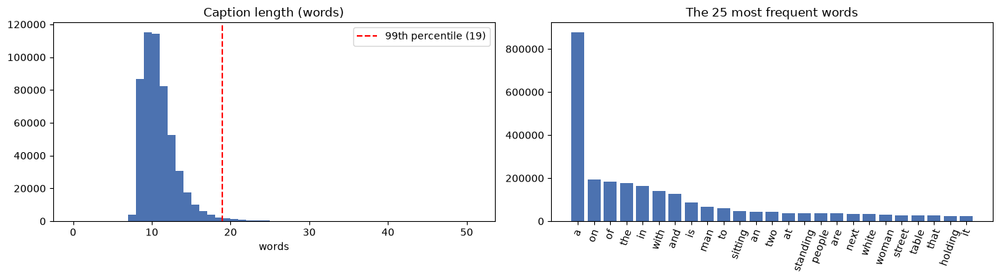

[Block 4a] OK


In [16]:
print("[Block 4a] Cleaning and vocabulary : starting...")

def clean_caption(text):
    # Lower case, only letters / digits / spaces (also used for BLEU)
    return " ".join(re.sub(r"[^a-z0-9 ]", " ", text.lower()).split())

def mark(text):
    return f"{MARK_START} {text} {MARK_END}"

for table in (train_df, val_df, test_df):
    table["clean"] = table["captions"].apply(lambda caps: [clean_caption(c) for c in caps])

train_caps = train_df.explode("clean")   # one row per caption
lengths = train_caps["clean"].str.split().str.len()
MAX_WORDS = int(np.percentile(lengths, 99))   # max caption length
SEQ_LEN = MAX_WORDS + 2                       # + ssss + eeee

word_counts = Counter(w for c in train_caps["clean"] for w in c.split())
vectorizer = layers.TextVectorization(max_tokens=NUM_WORDS, standardize=None, split="whitespace",
                                      output_mode="int", output_sequence_length=SEQ_LEN)
vectorizer.adapt(train_caps["clean"].map(mark).to_numpy())
VOCAB = [str(w) for w in vectorizer.get_vocabulary()]   # VOCAB[number] = word
WORD_INDEX = {w: i for i, w in enumerate(VOCAB)}
TOKEN_START, TOKEN_END = WORD_INDEX[MARK_START], WORD_INDEX[MARK_END]
VOCAB_SIZE = len(VOCAB)                  # <= NUM_WORDS

covered = sum(n for w, n in word_counts.items() if w in WORD_INDEX) / sum(word_counts.values())
print(f"  {len(word_counts):,} different words in the training captions, vocabulary: {len(VOCAB):,} "
      f"-> {covered:.2%} of the words written are known")
print(f"  caption length: median {int(lengths.median())} words, 99th percentile {MAX_WORDS} -> SEQ_LEN = {SEQ_LEN}")
print(f"  ssss = {TOKEN_START}, eeee = {TOKEN_END}, first words: {VOCAB[:12]}")

# One captioning model per CNN. v1 = the tutorial (results/caption_Hvass_GRU_InceptionV3.keras), v2 = with dropout,
# v3 = first attention model (results/caption_Attention_GRU_InceptionV3.keras), v4 = Show, Attend and Tell
MODEL_NAME = f"ShowAttendTell_{ENCODER.removesuffix('_grid')}" if ATTENTION else f"Hvass_GRU_{ENCODER}_v2"

# Saved for 04_pipeline.ipynb: same vocabulary and same CNN needed in production
with open(RESULTS / f"caption_{MODEL_NAME}_vocab.json", "w") as f:
    json.dump({"vocab": VOCAB, "max_words": MAX_WORDS, "mark_start": MARK_START, "mark_end": MARK_END,
               "encoder": ENCODER, "model": f"caption_{MODEL_NAME}.keras"}, f)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
ax1.hist(lengths, bins=range(0, lengths.max() + 2), color="#4c72b0")
ax1.axvline(MAX_WORDS, color="red", ls="--", label=f"99th percentile ({MAX_WORDS})")
ax1.set_title("Caption length (words)"); ax1.set_xlabel("words"); ax1.legend()
top = pd.Series(dict(word_counts.most_common(25)))
ax2.bar(top.index, top.values, color="#4c72b0"); ax2.tick_params(axis="x", rotation=70)
ax2.set_title("The 25 most frequent words")
plt.tight_layout()
plt.show()

print("[Block 4a] OK")

### 4.1 Training pairs

The network learns to **predict the next word**. For `ssss a dog runs eeee`:

| input | word to predict |
|---|---|
| `ssss` | `a` |
| `ssss a` | `dog` |
| `ssss a dog` | `runs` |
| `ssss a dog runs` | `eeee` |

So: input = caption without its last word, target = caption shifted by one word. One example = (CNN vector,
one caption). Every caption is used once per epoch.

The batches are made by a small `PyDataset` class: it shuffles the **images** at each epoch and keeps the 5
captions of an image side by side. A batch of 384 captions then reads only about 77 images from the disk,
which matters for the 27 GB grid file.

In [17]:
print("[Block 4b] Training pairs : starting...")

def caption_table(table):
    # One row per (image, caption): image index + caption as numbers
    rows = table.reset_index(drop=True).explode("clean").reset_index(names="img_idx")
    rows = rows[rows["clean"].str.split().str.len() <= MAX_WORDS]   # remove too long captions
    tokens = vectorizer(rows["clean"].map(mark).to_numpy()).numpy().astype("int32")
    return rows["img_idx"].to_numpy("int32"), tokens

class CaptionBatches(keras.utils.PyDataset):
    # Batches of (CNN features, caption) for model.fit
    def __init__(self, features, table, shuffle=False):
        super().__init__(workers=4)   # 4 threads prepare the next batches during training
        self.features, self.shuffle = features, shuffle
        self.img_idx, self.tokens = caption_table(table)   # sorted by image
        first = np.flatnonzero(np.diff(self.img_idx)) + 1
        self.per_image = np.split(np.arange(len(self.img_idx)), first)   # caption rows of each image
        self.rng = np.random.default_rng(SEED)
        self.on_epoch_end()

    def on_epoch_end(self):
        # New order of the images at each epoch (training only), the captions of an image stay together
        order = self.rng.permutation(len(self.per_image)) if self.shuffle else range(len(self.per_image))
        self.rows = np.concatenate([self.per_image[i] for i in order])

    def __len__(self):
        return int(np.ceil(len(self.rows) / BATCH))

    def __getitem__(self, k):
        rows = self.rows[k * BATCH:(k + 1) * BATCH]
        images, where = np.unique(self.img_idx[rows], return_inverse=True)   # each image read once
        feats = np.asarray(self.features[images], dtype="float32")[where]
        t = self.tokens[rows]                               # padding (0) is masked by the network
        x = {"transfer_values_input": feats, "decoder_input": t[:, :-1]}   # ssss a dog runs
        return x, t[:, 1:]                                                 # a dog runs eeee

train_ds = CaptionBatches(feats_train, train_df, shuffle=True)
val_ds = CaptionBatches(feats_val, val_df)
n_train_caps, n_val_caps = len(train_ds.rows), len(val_ds.rows)
print(f"  train: {n_train_caps} captions ({len(train_ds)} batches of {BATCH}), val: {n_val_caps} captions")

x, y = train_ds[0]
print("  transfer values:", x["transfer_values_input"].shape, "| decoder input:", x["decoder_input"].shape,
      "| target:", y.shape)
print("  example input :", " ".join(VOCAB[t] for t in x["decoder_input"][0] if t))
print("  example target:", " ".join(VOCAB[t] for t in y[0] if t))

print("[Block 4b] OK")


[Block 4b] Training pairs : starting...
  train: 526909 captions (1373 batches of 384), val: 58538 captions
  transfer values: (384, 49, 1024) | decoder input: (384, 20) | target: (384, 20)
  example input : ssss man in black jacket and skis kneeling on snowy road eeee
  example target: man in black jacket and skis kneeling on snowy road eeee
[Block 4b] OK


## 5. The Captioning Network

### v1 / v2: the tutorial's network (Hvass #22), one vector per image

```txt
 image ──> InceptionV3 (2048) ──> Dense 512 tanh ──┐ initial state
                                                   ▼
 words ──> Embedding (256) ──> Dropout ──> GRU 512 ──> GRU 512 ──> GRU 512 ──> Dropout ──> Dense softmax
```

- **Image -> RNN**: a Dense layer reduces the 2,048 numbers to 512, the size of the GRU memory. This vector is
  the **initial state** of the GRU layers: the network "knows" the image before reading any word.
- **Embedding**: each word number becomes a vector of 256 numbers, learned during training.
- **GRU**: reads the words one by one and keeps a memory (512 numbers). Its gates choose what to keep or forget,
  which works better than a simple RNN on long sentences.
- **Dropout** (v2): during training, 30 % of the values are set to 0 at random. The network cannot rely on a few
  values only, which reduces overfitting (the v1 had a gap of +0.37 between train and validation loss).
- **Output**: softmax over the vocabulary = probability of each possible next word.

### v3: first attention model (kept for comparison)

Our first try (`Attention_GRU_InceptionV3`) put the attention **after** the GRU layers. Result (sections 7.3 and
7.4): the attention was almost flat, and the words for objects ("pizza", "horse") were the *least* focused. The
reason: the GRU already had a summary of the whole image (initial state), and the attention only came at the
very end, so it never guided the choice of the next words.

### v4: Show, Attend and Tell (Xu et al. 2015)

The attention moves **inside** the GRU. Before **each** word:

1. the GRU memory $h$ (what has been written so far) gives a score to each region of the image:
   score $= v^\top \tanh(W_1\,\text{region} + W_2\,h)$ (Bahdanau attention);
2. a softmax turns the scores into weights $\alpha$ that sum to 1;
3. the **context** is the weighted mean of the regions; a **gate** (a number between 0 and 1, learned) says how
   much image information to use for this word ("a" and "of" need little, "giraffe" needs a lot);
4. the GRU reads the **word + the context**, and updates its memory.

So the context changes the memory, and the memory chooses the next regions to look at: what has been written
guides where to look next. This is the custom layer `AttentionGRU` below (the rest uses standard Keras layers).

```txt
 grid (R x D) ──> LayerNorm ──> Dense 512 relu ──> regions (R x 512)
                                     │                 │
                                     └──> mean ──> Dense 512 tanh ──> initial state
                                                       │                 │
 words ──> Embedding ──> Dropout ─────────────────> AttentionGRU 512 <───┘
                │                                       │ for each word: weights α, context, new memory h
                └─────────────────> Concatenate [h, context, word]
                                                │
                                   Dropout ──> Dense 512 tanh ──> Dense softmax
```

The 3 GRU layers of v1 become **one** GRU with attention, as in the article. It is slower to train (one step
per word, written in Python with `tf.scan`, instead of the fast GPU kernel of `layers.GRU`).

**Loss**: sparse categorical cross-entropy (a classification over the vocabulary, for each word), padding ignored.
**Optimizer** (v2): Adam, learning rate 1e-3, with gradient clipping (`clipnorm=5`): a very large gradient, which
happens with RNNs, is scaled down instead of breaking the training.


[Block 5] Captioning network : definition...


Model: "ShowAttendTell_ConvNeXtBase"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ transfer_values_in… │ (None, 49, 1024)  │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_regions_no… │ (None, 49, 1024)  │      2,048 │ transfer_values_… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_input       │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_regions     │ (None, 49, 512)   │    524,800 │ decoder_regions_… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_embedding   │ (None, None, 256) │  2,560,000 │ decoder_input[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_image_mean  │ (None, 512)       │          0 │ decoder_regions[… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_embedding_… │ (None, None, 256) │          0 │ decoder_embeddin… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_transfer_m… │ (None, 512)       │    262,656 │ decoder_image_me… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_attention   │ [(None, None,     │  2,494,977 │ decoder_embeddin… │
│ (AttentionGRU)      │ 512), (None,      │            │ decoder_regions[… │
│                     │ None, 512),       │            │ decoder_transfer… │
│                     │ (None, None, 49)] │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_concat      │ (None, None,      │          0 │ decoder_attentio… │
│ (Concatenate)       │ 1280)             │            │ decoder_attentio… │
│                     │                   │            │ decoder_embeddin… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_dropout     │ (None, None,      │          0 │ decoder_concat[0… │
│ (Dropout)           │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_combine     │ (None, None, 512) │    655,872 │ decoder_dropout[… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_output      │ (None, None,      │  5,130,000 │ decoder_combine[… │
│ (Dense)             │ 10000)            │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 11,630,353 (44.37 MB)

 Trainable params: 11,630,353 (44.37 MB)

 Non-trainable params: 0 (0.00 B)

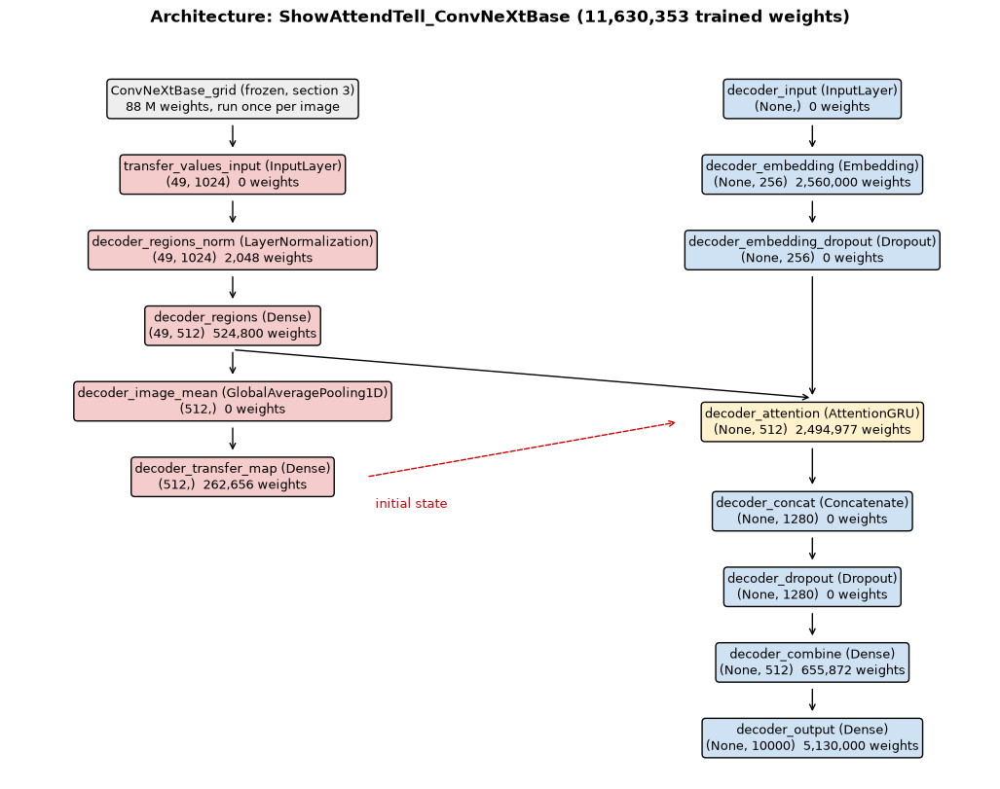

[Block 5] OK


In [18]:
print("[Block 5] Captioning network : definition...")

def build_hvass_decoder(name=None):
    name = name or MODEL_NAME
    # Same as the tutorial (connect_decoder), in Keras 3, with padding masked, + dropout (v2)
    transfer_values_input = keras.Input(shape=FEATURE_SHAPE, name="transfer_values_input")
    decoder_input = keras.Input(shape=(None,), dtype="int32", name="decoder_input")

    # Image vector -> initial state of the GRU layers
    initial_state = layers.Dense(STATE_SIZE, activation="tanh", name="decoder_transfer_map")(transfer_values_input)

    net = layers.Embedding(VOCAB_SIZE, EMBEDDING_SIZE, mask_zero=True, name="decoder_embedding")(decoder_input)
    net = layers.Dropout(DROPOUT, name="decoder_embedding_dropout")(net)
    for i in (1, 2, 3):
        net = layers.GRU(STATE_SIZE, return_sequences=True, name=f"decoder_gru{i}")(net, initial_state=initial_state)
    net = layers.Dropout(DROPOUT, name="decoder_dropout")(net)
    decoder_output = layers.Dense(VOCAB_SIZE, activation="softmax", name="decoder_output")(net)
    return keras.Model({"transfer_values_input": transfer_values_input, "decoder_input": decoder_input},
                       decoder_output, name=name)

@keras.saving.register_keras_serializable(package="Leyenda")
class AttentionGRU(layers.Layer):
    """GRU that looks at the image regions before writing each word (Show, Attend and Tell).

    Inputs: [words (batch, T, E), regions (batch, R, D), initial state (batch, units)]
    Outputs: [GRU states (batch, T, units), contexts (batch, T, D), attention weights (batch, T, R)]
    """
    def __init__(self, units, **kwargs):
        super().__init__(**kwargs)
        self.units = units
        self.supports_masking = True   # padding steps are skipped (state unchanged)
        self.att_regions = layers.Dense(units, use_bias=False, name="att_regions")   # region -> attention space
        self.att_state = layers.Dense(units, name="att_state")                       # GRU memory -> attention space
        self.att_score = layers.Dense(1, use_bias=False, name="att_score")           # one score per region
        self.gate = layers.Dense(1, activation="sigmoid", name="gate")               # how much image to use (0 to 1)
        self.cell = layers.GRUCell(units, name="cell")                               # one GRU step

    def build(self, input_shape):
        words, regions, _ = input_shape
        self.att_regions.build(regions)
        self.att_state.build((None, self.units))
        self.att_score.build((None, None, self.units))
        self.gate.build((None, self.units))
        self.cell.build((None, words[-1] + regions[-1]))   # input of the GRU = word + context

    def call(self, inputs, mask=None, training=False):
        words, regions, h0 = inputs
        keys = self.att_regions(regions)   # computed once per image
        m = mask[0] if isinstance(mask, (list, tuple)) else mask
        m = ops.ones(ops.shape(words)[:2]) if m is None else ops.cast(m, words.dtype)
        u = self.units
        f = ops.shape(regions)[-1]

        def step(previous, x):
            # previous = [h, context, alpha] side by side (tf.scan needs one tensor)
            h, (word, real) = previous[:, :u], x
            # 1. Attention: a score for each region, from the GRU memory h (what was written so far)
            scores = self.att_score(ops.tanh(keys + self.att_state(h)[:, None, :]))[..., 0]
            alpha = ops.softmax(scores, axis=-1)                                # R weights that sum to 1
            context = self.gate(h) * ops.sum(alpha[..., None] * regions, axis=1)   # weighted mean of the regions
            # 2. GRU step: reads the word AND the context
            new_h = self.cell(ops.concatenate([word, context], axis=-1), [h], training=training)[1][0]
            h = real[:, None] * new_h + (1 - real[:, None]) * h               # padding: keep the old state
            return ops.concatenate([h, context, alpha], axis=-1)

        start = ops.concatenate([h0, ops.zeros_like(regions[:, 0]), ops.zeros_like(regions[:, :, 0])], axis=-1)
        out = tf.scan(step, (ops.transpose(words, (1, 0, 2)), ops.transpose(m, (1, 0))), initializer=start)
        out = ops.transpose(out, (1, 0, 2))   # (batch, T, units + D + R)
        return out[..., :u], out[..., u:u + f], out[..., u + f:]

    def compute_mask(self, inputs, mask=None):
        m = mask[0] if isinstance(mask, (list, tuple)) else mask
        return [m, m, m]

    def compute_output_shape(self, input_shape):
        words, regions, _ = input_shape
        return ((words[0], words[1], self.units), (words[0], words[1], regions[-1]),
                (words[0], words[1], regions[1]))

    def get_config(self):
        return {**super().get_config(), "units": self.units}

def build_show_attend_tell(name=None):
    name = name or MODEL_NAME
    # v4: the regions of the image are read before each word (AttentionGRU)
    transfer_values_input = keras.Input(shape=FEATURE_SHAPE, name="transfer_values_input")   # (regions, numbers)
    decoder_input = keras.Input(shape=(None,), dtype="int32", name="decoder_input")

    regions = layers.LayerNormalization(name="decoder_regions_norm")(transfer_values_input)
    regions = layers.Dense(STATE_SIZE, activation="relu", name="decoder_regions")(regions)   # (regions, 512)
    image = layers.GlobalAveragePooling1D(name="decoder_image_mean")(regions)                # summary of the image
    initial_state = layers.Dense(STATE_SIZE, activation="tanh", name="decoder_transfer_map")(image)

    words = layers.Embedding(VOCAB_SIZE, EMBEDDING_SIZE, mask_zero=True, name="decoder_embedding")(decoder_input)
    words = layers.Dropout(DROPOUT, name="decoder_embedding_dropout")(words)
    states, contexts, _ = AttentionGRU(STATE_SIZE, name="decoder_attention")([words, regions, initial_state])

    # Next word from: the memory, what the network looked at, and the current word
    net = layers.Concatenate(name="decoder_concat")([states, contexts, words])
    net = layers.Dropout(DROPOUT, name="decoder_dropout")(net)
    net = layers.Dense(STATE_SIZE, activation="tanh", name="decoder_combine")(net)
    decoder_output = layers.Dense(VOCAB_SIZE, activation="softmax", name="decoder_output")(net)
    return keras.Model({"transfer_values_input": transfer_values_input, "decoder_input": decoder_input},
                       decoder_output, name=name)

# Position of each layer in the diagram: (x, y)
LAYOUTS = {
    "hvass": {"boxes": {"transfer_values_input": (2.5, 6.5), "decoder_transfer_map": (2.5, 4.5),
                        "decoder_input": (9, 8.6), "decoder_embedding": (9, 7.5),
                        "decoder_embedding_dropout": (9, 6.4), "decoder_gru1": (9, 5.3), "decoder_gru2": (9, 4.2),
                        "decoder_gru3": (9, 3.1), "decoder_dropout": (9, 2.0), "decoder_output": (9, 0.9)},
              "arrows": [("transfer_values_input", "decoder_transfer_map"), ("decoder_input", "decoder_embedding"),
                         ("decoder_embedding", "decoder_embedding_dropout"), ("decoder_embedding_dropout", "decoder_gru1"),
                         ("decoder_gru1", "decoder_gru2"), ("decoder_gru2", "decoder_gru3"),
                         ("decoder_gru3", "decoder_dropout"), ("decoder_dropout", "decoder_output")],
              "grus": ("decoder_gru1", "decoder_gru2", "decoder_gru3")},
    "attention": {"boxes": {"transfer_values_input": (2.5, 7.5), "decoder_regions_norm": (2.5, 6.4),
                            "decoder_regions": (2.5, 5.3), "decoder_image_mean": (2.5, 4.2),
                            "decoder_transfer_map": (2.5, 3.1), "decoder_input": (9, 8.6), "decoder_embedding": (9, 7.5),
                            "decoder_embedding_dropout": (9, 6.4), "decoder_attention": (9, 3.9),
                            "decoder_concat": (9, 2.6), "decoder_dropout": (9, 1.5), "decoder_combine": (9, 0.4),
                            "decoder_output": (9, -0.7)},
                  "arrows": [("transfer_values_input", "decoder_regions_norm"), ("decoder_regions_norm", "decoder_regions"),
                             ("decoder_regions", "decoder_image_mean"), ("decoder_image_mean", "decoder_transfer_map"),
                             ("decoder_input", "decoder_embedding"), ("decoder_embedding", "decoder_embedding_dropout"),
                             ("decoder_embedding_dropout", "decoder_attention"), ("decoder_regions", "decoder_attention"),
                             ("decoder_attention", "decoder_concat"), ("decoder_concat", "decoder_dropout"),
                             ("decoder_dropout", "decoder_combine"), ("decoder_combine", "decoder_output")],
                  "grus": ("decoder_attention",)},
}
IMAGE_LAYERS = {"transfer_values_input", "decoder_transfer_map", "decoder_image_mean", "decoder_regions",
                "decoder_regions_norm"}

def draw_captioning_architecture(model):
    # Diagram of the 2 branches: image (red), text (blue), attention (yellow)
    layout = LAYOUTS["attention" if ATTENTION else "hvass"]
    boxes = layout["boxes"]
    fig, ax = plt.subplots(figsize=(13, 10))
    ax.set_xlim(0, 11); ax.set_ylim(-1.3, 9.6); ax.axis("off")
    x_in, y_in = boxes["transfer_values_input"]
    ax.text(x_in, y_in + 1.1, f"{encoder.name} (frozen, section 3)\n{encoder.count_params() / 1e6:.0f} M weights, run once per image",
            ha="center", va="center", fontsize=9, bbox=dict(boxstyle="round", fc="#eeeeee"))
    ax.annotate("", xy=(x_in, y_in + 0.35), xytext=(x_in, y_in + 0.75), arrowprops=dict(arrowstyle="->"))
    for layer in model.layers:
        x, y = boxes[layer.name]
        output = layer.output[0] if isinstance(layer.output, (list, tuple)) else layer.output
        color = "#f4cccc" if layer.name in IMAGE_LAYERS else "#fff2cc" if layer.name == "decoder_attention" else "#cfe2f3"
        ax.text(x, y, f"{layer.name} ({type(layer).__name__})\n{tuple(output.shape[1:])}  {layer.count_params():,} weights",
                ha="center", va="center", fontsize=9, bbox=dict(boxstyle="round", fc=color))
    for a, b in layout["arrows"]:
        (xa, ya), (xb, yb) = boxes[a], boxes[b]
        if ya == yb:   # same line: from the side
            start, end = (xa + 1.5 * np.sign(xb - xa), ya), (xb - 1.5 * np.sign(xb - xa), yb)
        else:
            start, end = (xa, ya - 0.35), (xb, yb + 0.35)
        ax.annotate("", xy=end, xytext=start, arrowprops=dict(arrowstyle="->"))
    xs, ys = boxes["decoder_transfer_map"]
    for g in layout["grus"]:   # initial state arrows
        ax.annotate("", xy=(boxes[g][0] - 1.5, boxes[g][1]), xytext=(xs + 1.5, ys),
                    arrowprops=dict(arrowstyle="->", color="#cc0000", ls="--"))
    ax.text(xs + 1.6, ys - 0.45, "initial state", color="#cc0000", fontsize=9)
    ax.set_title(f"Architecture: {model.name} ({model.count_params():,} trained weights)", fontweight="bold")
    plt.show()

decoder = build_show_attend_tell() if ATTENTION else build_hvass_decoder()
decoder.summary()
draw_captioning_architecture(decoder)

print("[Block 5] OK")


### 5.1 Writing a caption

During training the network gets the right previous words. To write a new caption, it uses its own words:
start with `ssss`, predict a word, add it to the input, and repeat until `eeee`.

Two ways to choose the word:
- **greedy**: always the most probable word (fast);
- **beam search**: keep the 5 best sentences at each step, return the best one at the end (usually better).

The attention model is used the same way: same inputs, same functions. The `vocab` parameter gives the
vocabulary of an older model (section 7 evaluates all the saved models).

In [19]:
print("[Block 5.1] Caption generation : definition...")

def tokens_to_text(tokens, vocab=None):
    # Numbers -> sentence (stops at eeee)
    vocab = vocab or VOCAB
    words = []
    for t in tokens[1:]:
        if t == TOKEN_END or t == 0:
            break
        words.append(vocab[t])
    return " ".join(words)

def next_word_probs(model, feats, tokens):
    # Probabilities of the next word (last position)
    out = model({"transfer_values_input": feats, "decoder_input": tokens}, training=False)
    return np.array(out[:, -1], dtype="float64")

def greedy_captions(model, features, max_words=None, batch=500, vocab=None):
    max_words = max_words or MAX_WORDS
    captions = []
    for s in range(0, len(features), batch):
        feats = np.asarray(features[s:s + batch], dtype="float32")
        tokens = np.zeros((len(feats), max_words + 2), dtype="int32")
        tokens[:, 0] = TOKEN_START
        done = np.zeros(len(feats), dtype=bool)
        for t in range(max_words + 1):
            probs = next_word_probs(model, feats, tokens[:, :t + 1])
            probs[:, :2] = 0                       # never padding or [UNK]
            word = probs.argmax(axis=1)
            word[done] = 0                          # finished captions get padding
            tokens[:, t + 1] = word
            done |= word == TOKEN_END
            if done.all():
                break
        captions += [tokens_to_text(row, vocab) for row in tokens]
    return captions

def beam_captions(model, features, beam=BEAM, max_words=None, alpha=0.7, batch=200, vocab=None):
    max_words, V = max_words or MAX_WORDS, model.output_shape[-1]   # V = vocabulary size of this model
    captions = []
    for s in range(0, len(features), batch):
        feats = np.repeat(np.asarray(features[s:s + batch], dtype="float32"), beam, axis=0)   # 1 copy per beam
        B = len(feats) // beam
        tokens = np.zeros((B * beam, max_words + 2), dtype="int32")
        tokens[:, 0] = TOKEN_START
        score = np.full((B, beam), -1e9); score[:, 0] = 0.0   # log-probability of each sentence
        length = np.zeros((B, beam))
        done = np.zeros((B, beam), dtype=bool)
        for t in range(max_words + 1):
            logp = np.log(np.maximum(next_word_probs(model, feats, tokens[:, :t + 1]), 1e-12)).reshape(B, beam, V)
            logp[..., :2] = -1e9                                  # never padding or [UNK]
            cand = np.where(done[..., None], -1e9, score[..., None] + logp)
            cand[..., 0] = np.where(done, score, -1e9)            # finished sentences stay unchanged
            flat = cand.reshape(B, beam * V)
            best = np.argsort(-flat, axis=1)[:, :beam]            # keep the best candidates
            src, word = best // V, best % V
            tokens = tokens[(np.arange(B)[:, None] * beam + src).ravel()]
            tokens[:, t + 1] = word.ravel()
            score = np.take_along_axis(flat, best, axis=1)
            was_done = np.take_along_axis(done, src, axis=1)
            length = np.take_along_axis(length, src, axis=1) + ~was_done
            done = was_done | (word == TOKEN_END)
            if done.all():
                break
        pick = (score / np.maximum(length, 1) ** alpha).argmax(axis=1)   # normalized by length
        captions += [tokens_to_text(tokens[b * beam + pick[b]], vocab) for b in range(B)]
    return captions

def bleu_scores(references, hypotheses):
    # Corpus BLEU-1 to 4 (0 = nothing in common with the human captions, 1 = identical)
    refs = [[r.split() for r in rs] for rs in references]
    hyps = [h.split() for h in hypotheses]
    return {f"BLEU-{n}": corpus_bleu(refs, hyps, weights=tuple([1 / n] * n)) for n in (1, 2, 3, 4)}

def cider_score(references, hypotheses):
    # CIDEr (reference score of COCO): like BLEU, but rare words ("giraffe") count more than common ones ("a").
    # 0 = nothing in common, about 1 = as good as a human caption (it can go above 1)
    gts = {i: list(refs) for i, refs in enumerate(references)}
    res = {i: [hyp] for i, hyp in enumerate(hypotheses)}
    return Cider().compute_score(gts, res)[0]

print("  before training:", greedy_captions(decoder, feats_val[:2]))   # random words

print("[Block 5.1] OK")

[Block 5.1] Caption generation : definition...
  before training: ['eclectic eclectic electronics toasters toasters toasters toasters toasters toasters toasters toasters toasters toasters toasters toasters toasters toasters toasters toasters toasters', 'be counter counter counter counter counter counter counter counter counter counter counter counter counter counter counter counter counter counter counter']
[Block 5.1] OK


## 6. Training

Callbacks (as in deliverables 1 and 2, adapted in v2):
- **BleuCallback**: writes captions for 1,000 validation images after each epoch and computes their BLEU-4.
- **ModelCheckpoint** and **EarlyStopping**: keep the epoch with the **lowest validation loss**, and stop after
  5 epochs without progress. We tried to select on the BLEU-4 (v3), but it is measured on 1,000 images only, so it
  moves by ±0.01 from one epoch to the next by chance: the training stopped at epoch 12 and kept epoch 8, while
  the validation loss (measured on 59,000 captions, much more stable) was still falling.
- **ReduceLROnPlateau**: halves the learning rate as soon as the validation loss stops falling (1 epoch). In v1 the
  BLEU-4 jumped after each halving.

We also measure the **top-5 accuracy**: is the right word among the 5 most probable ones? (explained in 6.3)

`RETRAIN = False` reloads the saved model instead of training it again. The model file is
`results/caption_<MODEL_NAME>.keras`.


In [20]:
print("[Block 6] Training function : definition...")

# True = train again, False = reload the saved model
RETRAIN = {"ShowAttendTell_ConvNeXtBase": True, "ShowAttendTell_InceptionV3": True,
           "Hvass_GRU_InceptionV3_v2": True, "Hvass_GRU_VGG16_v2": False}

models = {}   # the trained (or reloaded) models

class BleuCallback(keras.callbacks.Callback):
    # BLEU-4 on validation images at each epoch (written in the CSV log)
    def __init__(self, features, table, n=1000):
        super().__init__()
        self.features, self.refs = np.asarray(features[:n], dtype="float32"), table["clean"].iloc[:n].tolist()
    def on_epoch_end(self, epoch, logs=None):
        hyps = greedy_captions(self.model, self.features)
        logs["val_bleu4"] = bleu_scores(self.refs, hyps)["BLEU-4"]
        print(f"  val BLEU-4 = {logs['val_bleu4']:.4f} | e.g. '{hyps[0]}'")

def train(model, epochs=EPOCHS):
    ckpt = RESULTS / f"caption_{model.name}.keras"
    if not RETRAIN.get(model.name, True) and ckpt.exists():
        models[model.name] = keras.models.load_model(ckpt)
        print(f"{model.name}: reloaded from {ckpt} (RETRAIN = False)")
        return
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=LR, clipnorm=5.0),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy",   # share of next words predicted right
                           keras.metrics.SparseTopKCategoricalAccuracy(k=5, name="top5")],   # right word in the top 5
                  # XLA (the GPU compiler used by default) cannot compute the gradient of the tf.scan loop of
                  # AttentionGRU: it is switched off for the attention models only
                  jit_compile=not any(isinstance(layer, AttentionGRU) for layer in model.layers))
    callbacks = [
        BleuCallback(feats_val, val_df),   # first, so that the next callbacks see val_bleu4
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=1, min_lr=1e-5, verbose=1),
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
        keras.callbacks.ModelCheckpoint(str(ckpt), monitor="val_loss", save_best_only=True),
        keras.callbacks.CSVLogger(str(LOGS / f"caption_{model.name}_history.csv")),
        keras.callbacks.TensorBoard(log_dir=str(LOGS / f"caption_{model.name}")),
    ]
    start = time.time()
    history = model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=callbacks, verbose=2)
    print(f"{model.name}: trained in {(time.time() - start) / 60:.1f} min, {len(history.history['loss'])} epochs")
    models[model.name] = model

def plot_history(name):
    h = pd.read_csv(LOGS / f"caption_{name}_history.csv")
    best = h["val_loss"].idxmin()   # the epoch kept by ModelCheckpoint
    fig, axes = plt.subplots(1, 3, figsize=(18, 4))
    for ax, keys, title in [(axes[0], ["loss"], "loss (cross-entropy)"),
                            (axes[1], [k for k in ("accuracy", "top5") if k in h], "next-word accuracy (top-1, top-5)")]:
        for key in keys:
            ax.plot(h["epoch"] + 1, h[key], label=f"train {key}")
            ax.plot(h["epoch"] + 1, h[f"val_{key}"], label=f"validation {key}")
        ax.axvline(best + 1, color="grey", ls=":", label="best epoch (kept)")
        ax.set_title(f"{name} - {title}"); ax.set_xlabel("epoch"); ax.legend()
    axes[2].plot(h["epoch"] + 1, h["val_bleu4"], color="green", marker="o")
    axes[2].axvline(best + 1, color="grey", ls=":")
    axes[2].set_title(f"{name} - BLEU-4 (1,000 validation images, greedy)"); axes[2].set_xlabel("epoch")
    plt.tight_layout()
    plt.show()
    print(f"  best epoch {best + 1}: train loss {h.loss[best]:.3f}, val loss {h.val_loss[best]:.3f}, "
          f"gap {h.val_loss[best] - h.loss[best]:+.3f} | val accuracy {h.val_accuracy[best]:.3f} "
          f"(top-5 {h.get('val_top5', pd.Series(np.nan, h.index))[best]:.3f}) | "
          f"val BLEU-4 {h.val_bleu4[best]:.4f}")

print("[Block 6] OK")

[Block 6] Training function : definition...
[Block 6] OK


### 6.1 Training the captioning model

In [21]:
print(f"[Block 6.1] Training {MODEL_NAME} : starting...")

train(build_show_attend_tell() if ATTENTION else build_hvass_decoder())

print("[Block 6.1] OK")

[Block 6.1] Training ShowAttendTell_ConvNeXtBase : starting...
Epoch 1/50


I0000 00:00:1792579338.408036  131411 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


  val BLEU-4 = 0.2984 | e.g. 'a dog is laying on a bag of shoes'
1373/1373 - 423s - 308ms/step - accuracy: 0.4593 - loss: 2.9119 - top5: 0.6722 - val_accuracy: 0.5260 - val_loss: 2.2688 - val_top5: 0.7586 - val_bleu4: 0.2984 - learning_rate: 0.0010
Epoch 2/50
  val BLEU-4 = 0.3054 | e.g. 'a dog laying on top of a pair of shoes'
1373/1373 - 400s - 291ms/step - accuracy: 0.5319 - loss: 2.2051 - top5: 0.7656 - val_accuracy: 0.5437 - val_loss: 2.1223 - val_top5: 0.7783 - val_bleu4: 0.3054 - learning_rate: 0.0010
Epoch 3/50
  val BLEU-4 = 0.3181 | e.g. 'a dog laying on top of a pile of shoes'
1373/1373 - 400s - 291ms/step - accuracy: 0.5457 - loss: 2.0768 - top5: 0.7823 - val_accuracy: 0.5503 - val_loss: 2.0638 - val_top5: 0.7872 - val_bleu4: 0.3181 - learning_rate: 0.0010
Epoch 4/50
  val BLEU-4 = 0.3284 | e.g. 'a dog laying on top of a pair of shoes'
1373/1373 - 402s - 292ms/step - accuracy: 0.5539 - loss: 2.0027 - top5: 0.7919 - val_accuracy: 0.5541 - val_loss: 2.0402 - val_top5: 0.7911 

### 6.2 Training Curves

[Block 6.2] Training curves : starting...


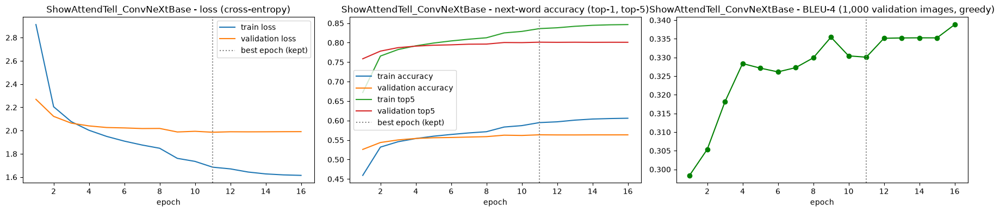

  best epoch 11: train loss 1.685, val loss 1.986, gap +0.301 | val accuracy 0.563 (top-5 0.801) | val BLEU-4 0.3301
[Block 6.2] OK


In [22]:
print("[Block 6.2] Training curves : starting...")

plot_history(MODEL_NAME)

print("[Block 6.2] OK")

### 6.3 Why does the accuracy stay around 55 %?

The accuracy here is the **next-word accuracy**: the network gets the right beginning of a human caption and must
guess the next word, and the answer is right only if it is **exactly** the word of this human caption.

But the 5 human captions of an image are all different:

| | next word after "a man ..." |
|---|---|
| human 1 | a man **riding** a wave on a surfboard |
| human 2 | a man **on** a surfboard in the ocean |
| human 3 | a man **surfing** a big wave |

Even a perfect network cannot know which of the 5 humans it is compared with. "riding", "on" and "surfing" are
all good answers, but only one counts as right. So the **accuracy can never reach 100 %**, and around 55 % is
already a good value.

That is why:
- the **top-5 accuracy** (right word in the 5 most probable ones) is much higher: the network has learned good
  probabilities, it just cannot guess which of the good words the human chose;
- we judge the network on **BLEU** and **CIDEr** (section 7), which compare the **whole sentence** written by
  the network alone with the **5** human captions at the same time;
- we keep the epoch with the best BLEU-4, not the best accuracy.


## 7. Evaluation on the Test Set (COCO val2017)

**BLEU** compares the generated caption with the 5 human captions: it counts the groups of 1 to 4 words they have
in common (score from 0 to 1). BLEU-4 is the strictest. For comparison, *Show and Tell* (Vinyals et al. 2015,
an architecture close to ours, trained on all of COCO) gets BLEU-4 ≈ 0.28.

**CIDEr** is the reference score of COCO: like BLEU it counts the common groups of words, but a rare word
("giraffe") counts more than a common one ("a", "on"). A network that writes generic sentences gets a good
BLEU but a low CIDEr. *Show and Tell* gets CIDEr ≈ 0.86.

**All the saved models** (`results/caption_*.keras`) are evaluated on the same 5,000 test images, with the
same beam width, so the table compares them fairly. The captions of each model are saved in
`results/captions/` and written again only when the model file changes.

Two simple baselines to compare with:
- **constant caption**: the most frequent training caption for every image;
- **nearest neighbour**: the caption of the most similar training image (cosine distance on the CNN vectors).

In [23]:
print("[Block 7] Evaluation : starting...")

model = models[MODEL_NAME]
test_refs = test_df["clean"].tolist()
results, generated = {}, {}

# Baseline 1: always the same caption
constant = train_caps["clean"].value_counts().index[0]
generated["Constant caption"] = [constant] * len(test_df)

# Baseline 2: caption of the most similar training image (cosine distance on the CNN vectors)
def normalize(f):
    f = np.asarray(f, dtype="float32")
    return f / np.linalg.norm(f, axis=1, keepdims=True)
train_unit, test_unit = normalize(pooled(feats_train)), normalize(pooled(feats_test))   # 1 vector per image
nearest = np.concatenate([(test_unit[s:s + 1000] @ train_unit.T).argmax(axis=1)
                          for s in range(0, len(test_unit), 1000)])
generated[f"Nearest neighbour ({ENCODER})"] = [train_df["clean"].iloc[i][0] for i in nearest]

# All the saved captioning models, greedy and beam search
CAPTIONS = RESULTS / "captions"   # captions of each model on the test set (cache)
CAPTIONS.mkdir(exist_ok=True)

def model_captions(name):
    # Greedy and beam captions of a saved model, written once then read from disk
    with open(RESULTS / f"caption_{name}_vocab.json") as f:
        config = json.load(f)
    model_file, cache = RESULTS / config["model"], CAPTIONS / f"{name}.csv"
    if cache.exists() and cache.stat().st_mtime > model_file.stat().st_mtime:
        table = pd.read_csv(cache, keep_default_na=False)
        if table["file_name"].tolist() == test_df["file_name"].tolist():
            print(f"  {name}: read from {cache}")
            return table
    features_file = FEATURES / f"{FEATURE_FILES[config['encoder']]}_test"
    if pd.read_csv(features_file.with_suffix(".csv"))["path"].tolist() != test_df["path"].tolist():
        raise ValueError(f"{features_file}: not the same test images, run section 3 with ENCODER = {config['encoder']}")
    features = np.load(features_file.with_suffix(".npy"), mmap_mode="r")
    m = models.get(name) or keras.models.load_model(model_file, compile=False)
    assert config["vocab"][TOKEN_START] == MARK_START and config["vocab"][TOKEN_END] == MARK_END
    start = time.time()
    table = pd.DataFrame({"file_name": test_df["file_name"],
                          "greedy": greedy_captions(m, features, vocab=config["vocab"]),
                          "beam": beam_captions(m, features, vocab=config["vocab"])})
    table.to_csv(cache, index=False)
    print(f"  {name}: {len(table)} images, captions written in {time.time() - start:.0f} s")
    return table

saved = sorted(p.name[len("caption_"):-len("_vocab.json")] for p in RESULTS.glob("caption_*_vocab.json"))
for name in saved:
    if not (RESULTS / f"caption_{name}.keras").exists():
        continue
    table = model_captions(name)
    generated[f"{name} greedy"] = table["greedy"].tolist()
    generated[f"{name} beam {BEAM}"] = table["beam"].tolist()
GREEDY, BEAM_LABEL = f"{MODEL_NAME} greedy", f"{MODEL_NAME} beam {BEAM}"   # the model of this run (sections 7.1+)

for label, hyps in generated.items():
    results[label] = bleu_scores(test_refs, hyps)
    results[label]["CIDEr"] = cider_score(test_refs, hyps)
    results[label]["distinct captions"] = len(set(hyps)) / len(hyps)   # 1 = all different
    results[label]["words used"] = len({w for h in hyps for w in h.split()})
    results[label]["mean length"] = np.mean([len(h.split()) for h in hyps])

results = pd.DataFrame(results).T
display(results.round(4).style.highlight_max(subset=["BLEU-4", "CIDEr"], color="#c6efce"))
results.to_csv(RESULTS / "deliverable3_results.csv")

print("[Block 7] OK")


[Block 7] Evaluation : starting...


I0000 00:00:1792585858.146944  131712 cuda_dnn.cc:461] Loaded cuDNN version 92700


  Attention_GRU_InceptionV3: 5000 images, captions written in 436 s
  Hvass_GRU_InceptionV3: 5000 images, captions written in 495 s
  ShowAttendTell_ConvNeXtBase: 5000 images, captions written in 484 s


,BLEU-1,BLEU-2,BLEU-3,BLEU-4,CIDEr,distinct captions,words used,mean length
Constant caption,0.438600,0.216100,0.118500,0.075000,0.070400,0.000200,8.000000,10.000000
Nearest neighbour (ConvNeXtBase_grid),0.555700,0.357300,0.226700,0.143900,0.582800,0.937800,3202.000000,10.330800
Attention_GRU_InceptionV3 greedy,0.675100,0.492800,0.349100,0.247800,0.796400,0.654000,908.000000,9.485200
Attention_GRU_InceptionV3 beam 5,0.669700,0.491300,0.357700,0.264300,0.841000,0.501000,760.000000,9.662800
Hvass_GRU_InceptionV3 greedy,0.674100,0.494900,0.353500,0.253000,0.833000,0.768200,978.000000,9.834600
Hvass_GRU_InceptionV3 beam 5,0.669700,0.493900,0.363300,0.271700,0.864000,0.606800,826.000000,9.929800
ShowAttendTell_ConvNeXtBase greedy,0.748100,0.583800,0.440200,0.330100,1.090200,0.836200,1321.000000,9.644000
ShowAttendTell_ConvNeXtBase beam 5,0.733800,0.572800,0.440200,0.339200,1.118100,0.714800,1117.000000,9.857400


[Block 7] OK


### 7.1 Examples on Test Images

8 random test images: caption of the network (greedy and beam) and 2 human captions.

[Block 7.1] Examples : starting...


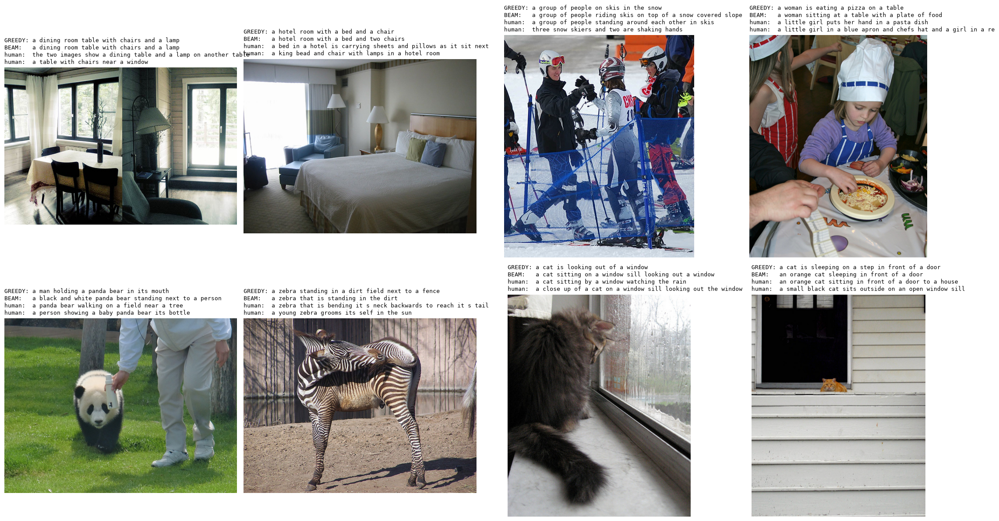

[Block 7.1] OK


In [24]:
print("[Block 7.1] Examples : starting...")

def show_examples(indices, extra=None):
    fig, axes = plt.subplots(2, 4, figsize=(22, 12))
    for ax, i in zip(axes.flat, indices):
        row = test_df.iloc[i]
        ax.imshow(iio.imread(row["path"]), cmap="gray")
        ax.axis("off")
        lines = [f"GREEDY: {generated[GREEDY][i]}", f"BEAM:   {generated[BEAM_LABEL][i]}",
                 f"human:  {row['clean'][0]}", f"human:  {row['clean'][1]}"]
        if extra is not None:
            lines.insert(0, extra[i])
        ax.set_title("\n".join(l[:70] for l in lines), fontsize=9, loc="left", family="monospace")
    plt.tight_layout()
    plt.show()

show_examples(np.random.default_rng().choice(len(test_df), size=8, replace=False))   # new images at each run

print("[Block 7.1] OK")

### 7.2 Best and Worst Captions

BLEU-4 per image (with smoothing): the 4 best and the 4 worst test images.

[Block 7.2] Best and worst : starting...


  first row: the 4 best, second row: the 4 worst


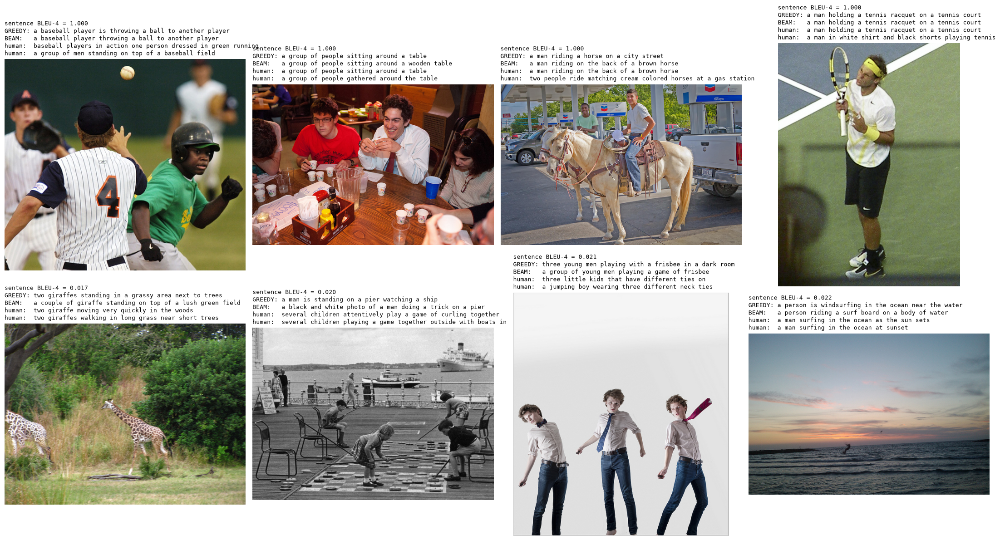

,times written
a man riding a wave on top of a surfboard,50
a man holding a tennis racquet on a tennis court,46
a close up of a plate of food on a table,31
a man riding skis down a snow covered slope,30
a couple of giraffe standing next to each other,28
a man riding a skateboard up the side of a ramp,26
a living room filled with furniture and a flat screen tv,24
a baseball player swinging a bat at a ball,21
a couple of elephants standing next to each other,20
a red stop sign sitting on the side of a road,18


[Block 7.2] OK


In [25]:
print("[Block 7.2] Best and worst : starting...")

smooth = SmoothingFunction().method1
sentence_scores = np.array([sentence_bleu([r.split() for r in refs], hyp.split(), smoothing_function=smooth)
                            for refs, hyp in zip(test_refs, generated[BEAM_LABEL])])
order = np.argsort(sentence_scores)
labels = {i: f"sentence BLEU-4 = {sentence_scores[i]:.3f}" for i in range(len(test_df))}
print("  first row: the 4 best, second row: the 4 worst"); show_examples(order[::-1][:4].tolist() + order[:4].tolist(), extra=labels)

# Most frequent generated captions (generic sentences)
display(pd.Series(generated[BEAM_LABEL]).value_counts().head(10).rename("times written").to_frame())

print("[Block 7.2] OK")

### 7.3 Where does the network look? (attention model only)

For each word it writes, the attention model gives **one weight per region** of the grid (8 x 8 = 64 for
InceptionV3, 7 x 7 = 49 for ConvNeXt).
The weights sum to 1: a region with weight 0.5 gives half of the information used to write the word.

We draw these weights on the image, as a heat map: **red = region used** to write the word, blue = region
ignored. If the network works well, it looks at the dog when it writes "dog", and at the grass when it writes
"grass".

How it works: we build a second model with the **same layers and the same weights**, whose output is the
attention weights instead of the next word. We give it the caption that was written, and get back the weights
used for each word.

**Read the colours with care**: the colour scale is stretched on each small image, so red only means *more
than the other regions*. The real strength is the **max** value in the title: 1 / number of regions (0.016 for 64,
0.020 for 49) means the network looks everywhere the same, 1 means it looks at one region only. Section 7.4 measures this on 1,000 images.

To test your own image, put its path in `MY_IMAGE`.


[Block 7.3] Attention maps : starting...


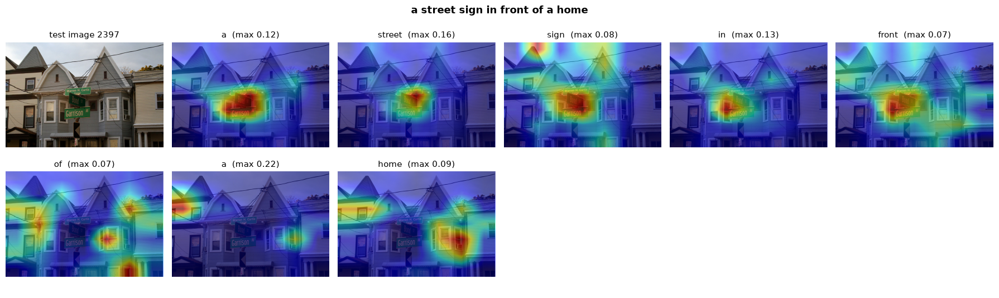

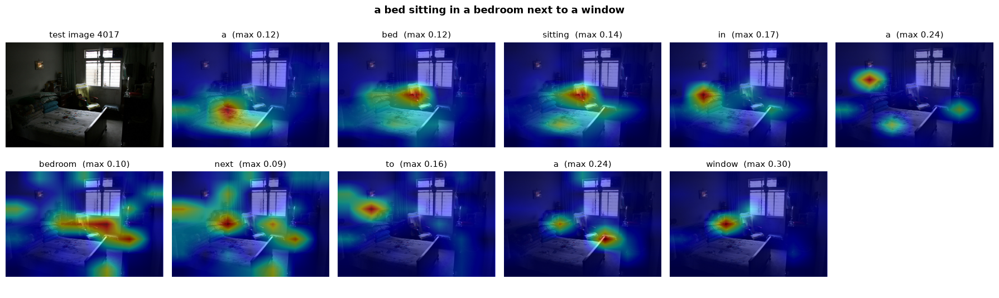

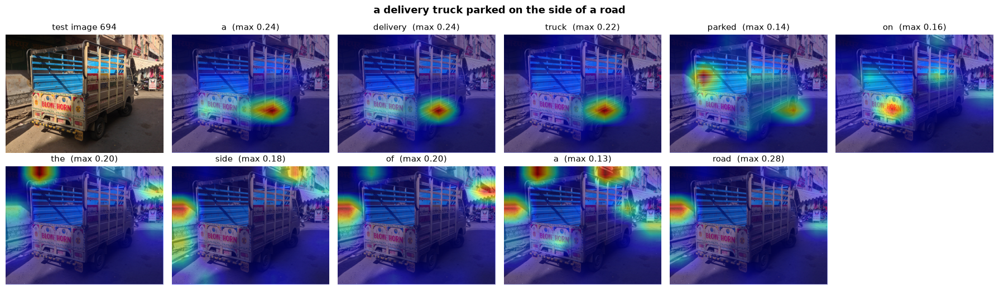

[Block 7.3] OK


In [26]:
print("[Block 7.3] Attention maps : starting...")

MY_IMAGE = None   # <- path of any image (e.g. "data_raw/my_photo.jpg"), None = random test images

def attention_weights(model, features, caption):
    # Attention weights used to write each word of the caption: (number of words, 64 regions)
    attention_model = keras.Model(model.inputs, model.get_layer("decoder_attention").output[-1])
    words = caption.split()
    tokens = np.array([[TOKEN_START] + [WORD_INDEX[w] for w in words]], dtype="int32")
    weights = attention_model({"transfer_values_input": np.asarray(features, dtype="float32")[None],
                               "decoder_input": tokens}, training=False)
    # Position t reads the words before t and writes word t -> weights[t] = weights used for words[t]
    return np.asarray(weights)[0, :len(words)]

def show_attention(image, caption, weights, title="", cols=6):
    # One small image per word, with its attention map on top
    grid = int(np.sqrt(weights.shape[1]))   # 8
    h, w = image.shape[:2]
    words = caption.split()
    rows = int(np.ceil((len(words) + 1) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(3 * cols, 2.7 * rows), squeeze=False)
    axes = axes.ravel()
    axes[0].imshow(image, cmap="gray"); axes[0].set_title(title or "image", fontsize=11)
    for ax, word, wt in zip(axes[1:], words, weights):
        ax.imshow(image, cmap="gray")
        # The CNN saw the image resized to a square: the 8 x 8 grid covers the whole image
        ax.imshow(wt.reshape(grid, grid), cmap="jet", alpha=0.5, interpolation="bilinear", extent=(0, w, h, 0))
        ax.set_title(f"{word}  (max {wt.max():.2f})", fontsize=11)
    for ax in axes:
        ax.axis("off")
    plt.suptitle(caption, fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()

def attention_on_file(path):
    # Any image file: CNN grid -> caption (beam search) -> attention maps
    features = encoder.predict(load_for_encoder(path)[None], verbose=0)[0]
    caption = beam_captions(model, features[None])[0]
    show_attention(iio.imread(path), caption, attention_weights(model, features, caption), title=Path(path).name)

if not ATTENTION:
    print('  only for the attention models (ENCODER = "..._grid")')
elif MY_IMAGE is not None:
    attention_on_file(MY_IMAGE)
else:
    for i in np.random.default_rng().choice(len(test_df), size=3, replace=False):   # new images at each run
        caption = generated[BEAM_LABEL][i]
        show_attention(iio.imread(test_df["path"].iloc[i]), caption,
                       attention_weights(model, feats_test[i], caption), title=f"test image {i}")

print("[Block 7.3] OK")


### 7.4 Is the attention focused? (attention model only)

The maps of 7.3 show a few images. Here we measure on 1,000 test images, for each word, **how focused** the
attention is: the **largest** of the 64 weights.
- If the network looks everywhere the same way, each region gets 1 / number of regions (**0.016** for 64,
  **0.020** for 49).
- If it looks at one single region, the largest weight is close to **1**.

We expect the words for **objects** ("giraffe", "pizza") to be focused on one region, and the small words
("a", "of", "the") to be spread out: to write "a", there is nothing in particular to look at.


[Block 7.4] Attention focus : starting...


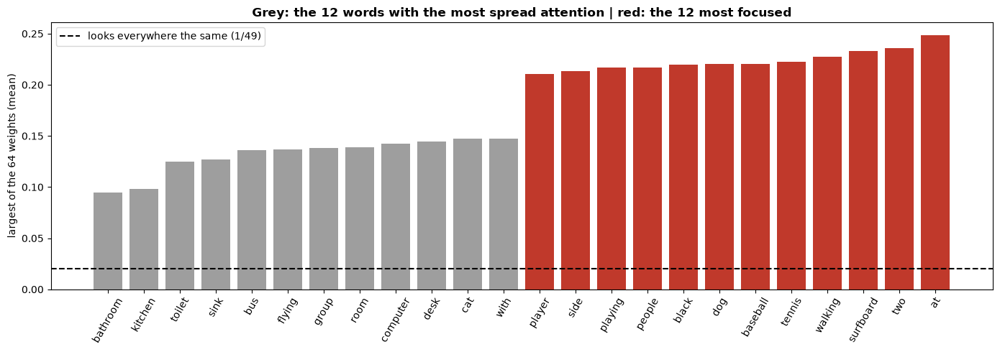

  76 words written at least 20 times | mean largest weight: 0.177 (uniform: 0.020)
[Block 7.4] OK


In [27]:
print("[Block 7.4] Attention focus : starting...")

if not ATTENTION:
    print('  only for the attention models (ENCODER = "..._grid")')
else:
    attention_model = keras.Model(model.inputs, model.get_layer("decoder_attention").output[-1])
    N_FOCUS = 1000
    focus = {}   # word -> list of largest weights
    for s in range(0, N_FOCUS, 100):
        captions = generated[GREEDY][s:s + 100]
        tokens = np.zeros((len(captions), MAX_WORDS + 1), dtype="int32")   # padding (0) is masked
        tokens[:, 0] = TOKEN_START
        for r, caption in enumerate(captions):
            ids = [WORD_INDEX[w] for w in caption.split()][:MAX_WORDS]
            tokens[r, 1:len(ids) + 1] = ids
        weights = np.asarray(attention_model({"transfer_values_input": np.asarray(feats_test[s:s + 100], dtype="float32"),
                                              "decoder_input": tokens}, training=False))   # (100, words, 64)
        for r, caption in enumerate(captions):
            for t, word in enumerate(caption.split()[:MAX_WORDS]):
                focus.setdefault(word, []).append(weights[r, t].max())

    focus = pd.DataFrame({"times written": {w: len(v) for w, v in focus.items()},
                          "largest weight (mean)": {w: np.mean(v) for w, v in focus.items()}})
    focus = focus[focus["times written"] >= 20].sort_values("largest weight (mean)")   # frequent words only
    shown = pd.concat([focus.head(12), focus.tail(12)])

    fig, ax = plt.subplots(figsize=(14, 5))
    colors = ["#9e9e9e"] * 12 + ["#c0392b"] * 12
    ax.bar(shown.index, shown["largest weight (mean)"], color=colors)
    uniform = 1 / FEATURE_SHAPE[0]
    ax.axhline(uniform, color="black", ls="--", label=f"looks everywhere the same (1/{FEATURE_SHAPE[0]})")
    ax.set_ylabel("largest of the 64 weights (mean)")
    ax.set_title("Grey: the 12 words with the most spread attention | red: the 12 most focused", fontweight="bold")
    ax.tick_params(axis="x", rotation=60); ax.legend()
    plt.tight_layout()
    plt.show()
    print(f"  {len(focus)} words written at least 20 times | mean largest weight: "
          f"{focus['largest weight (mean)'].mean():.3f} (uniform: {uniform:.3f})")

print("[Block 7.4] OK")


## 8. Robustness to Noise (link with Deliverable 2)

Does noise change the captions, and does the denoiser of deliverable 2 (`denoise_UNet_deep.keras`) help? On
500 test images, we compare the BLEU-4 of 3 versions of each image: **clean**, **noisy**, **denoised**.
The noises are those of deliverable 2 (Gaussian, salt and pepper, JPEG).

[Block 8] Robustness to noise : starting...


I0000 00:00:1792587349.775652  131725 service.cc:153] XLA service 0x560948b7acc0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792587349.775713  131725 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4090 Laptop GPU, Compute Capability 8.9 (Driver: 13.4.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1792587349.929752  131725 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1792587352.784540  214320 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_278', 8724 bytes spill stores, 8732 bytes spill loads

I0000 00:00:1792587354.187590  214307 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_170', 8416 bytes spill stores, 8424 bytes spill loads

I0000 00:00:1792587355.109901  214310 subprocess_compilation.

,BLEU-4 clean,BLEU-4 noisy,BLEU-4 denoised,"same caption as clean, noisy","same caption as clean, denoised"
gaussian 0.15,0.3372,0.3134,0.3116,0.258,0.218
salt & pepper 6 %,0.3372,0.3133,0.3275,0.252,0.460
JPEG quality 10,0.3372,0.3161,0.3113,0.236,0.206


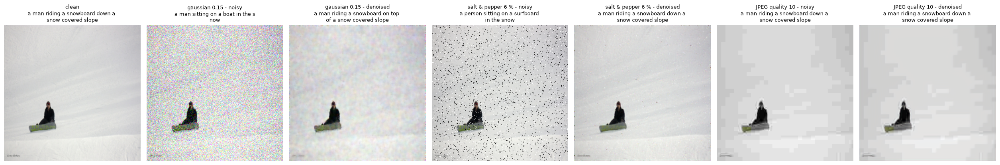

[Block 8] OK


In [28]:
print("[Block 8] Robustness to noise : starting...")

denoiser = keras.models.load_model(RESULTS / "denoise_UNet_deep.keras", compile=False)   # best model of D2
DENOISE_SIZE = tuple(denoiser.input_shape[1:3])   # 256 x 256
N_ROBUST = 500
rng = np.random.default_rng(SEED)

def load_01(path):
    # Same loading as deliverable 2: RGB, 256 x 256, pixels in [0, 1]
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.clip_by_value(tf.round(tf.image.resize(img, DENOISE_SIZE, antialias=True)), 0, 255)
    return img.numpy() / 255.0

# Noises of deliverable 2, at a fixed strong level
def gaussian(x):    return x + rng.normal(0, 0.15, x.shape)
def salt_pepper(x):
    u = rng.random(x.shape[:-1])[..., None]
    return np.where(u < 0.03, 1.0, np.where(u > 0.97, 0.0, x))
def jpeg(x):        return tf.image.adjust_jpeg_quality(x, 10).numpy()
NOISES = {"gaussian 0.15": gaussian, "salt & pepper 6 %": salt_pepper, "JPEG quality 10": jpeg}

def features_01(images):
    # Images in [0, 1] -> CNN vectors (same preprocessing as section 3)
    x = tf.image.resize(np.asarray(images, dtype="float32") * 255.0, IMG_SIZE)
    return encoder.predict(preprocess_input(x), batch_size=FEATURE_BATCH, verbose=0)

def denoise(images):
    return np.concatenate([denoiser(np.asarray(images[s:s + 32], dtype="float32"), training=False).numpy()
                           for s in range(0, len(images), 32)])

robust_idx = rng.choice(len(test_df), size=N_ROBUST, replace=False)
clean = np.stack([load_01(p) for p in test_df["path"].iloc[robust_idx]])
refs = [test_refs[i] for i in robust_idx]
robust, examples = {}, {}
caps = beam_captions(model, features_01(clean))
bleu_clean = bleu_scores(refs, caps)["BLEU-4"]
examples["clean"] = (clean[0], caps[0])
for name, noise_fn in NOISES.items():
    noisy = np.clip(np.stack([noise_fn(x) for x in clean]), 0, 1).astype("float32")
    denoised = denoise(noisy)
    caps_noisy, caps_denoised = beam_captions(model, features_01(noisy)), beam_captions(model, features_01(denoised))
    robust[name] = {"BLEU-4 clean": bleu_clean,
                    "BLEU-4 noisy": bleu_scores(refs, caps_noisy)["BLEU-4"],
                    "BLEU-4 denoised": bleu_scores(refs, caps_denoised)["BLEU-4"],
                    "same caption as clean, noisy": np.mean([a == b for a, b in zip(caps, caps_noisy)]),
                    "same caption as clean, denoised": np.mean([a == b for a, b in zip(caps, caps_denoised)])}
    examples[f"{name} - noisy"] = (noisy[0], caps_noisy[0])
    examples[f"{name} - denoised"] = (denoised[0], caps_denoised[0])

robust = pd.DataFrame(robust).T
display(robust.round(4))
robust.to_csv(RESULTS / f"deliverable3_robustness_{ENCODER}.csv")

fig, axes = plt.subplots(1, len(examples), figsize=(3.6 * len(examples), 4.5))
for ax, (title, (img, cap)) in zip(axes, examples.items()):
    ax.imshow(np.clip(img, 0, 1)); ax.axis("off")
    ax.set_title(f"{title}\n" + "\n".join(cap[i:i + 32] for i in range(0, len(cap), 32)), fontsize=9)
plt.tight_layout()
plt.show()

print("[Block 8] OK")

## 9. Conclusions

*Written after the run, from `results/deliverable3_results.csv`, `results/deliverable3_robustness_<ENCODER>.csv`
and the curves of section 6.2.*